# Финальный экзамен

Аяна Бастаева, MAF'28

Подробный финальный отчет в файле `Final_exam_Ayana.pdf`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from rink import plot_rink

pd.set_option('display.precision', 3)
pd.set_option('display.width', 120)

EMERALD = '#10805D'
BLUE = '#2B5E96'
AMBER = '#D99A1E'
SILVER = '#9AA5B1'

sns.set_theme(style='whitegrid', palette=[EMERALD, BLUE, AMBER, SILVER])
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']   # если Arial нет, используется похожий шрифт
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.edgecolor'] = '#B8C0C8'
plt.rcParams['grid.color'] = '#E8ECEF'
plt.rcParams['axes.labelcolor'] = '#333333'
plt.rcParams['xtick.color'] = '#555555'
plt.rcParams['ytick.color'] = '#555555'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['pdf.fonttype'] = 42

os.makedirs('figures', exist_ok=True)

## 1. Загрузка данных

Первый столбец файла содержит сохранённый номер строки, поэтому он использован как индекс (`index_col=0`). Без этого появляется лишний столбец, и столбцов становится 39.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Ниже проверено число матчей и типы событий.

In [4]:
print('Матчей:', events['Game ID'].nunique())
events['Play Type'].value_counts()

Матчей: 82


Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

В данных 82 матча. 

## 2. Сводная таблица по матчам

Дата и названия команд взяты из первой строки матча, внутри матча они не меняются. Накопленный счёт по ходу игры может только расти, поэтому итоговый счёт равен его максимуму. Число овертаймов определено по номеру последнего периода: 3 означает основное время, 4 означает один овертайм, 5 означает два.

In [5]:
grouped = events.groupby('Game ID')

games = grouped[['Date', 'Away Team', 'Home Team']].first()
games['Away Score'] = grouped['Cumulated Away Score'].max()
games['Home Score'] = grouped['Cumulated Home Score'].max()

last_period = grouped['Period'].max()
games['Outcome'] = 'Final'
games.loc[last_period == 4, 'Outcome'] = 'Final/OT'
# два овертайма и больше: Final/2OT, Final/3OT и тд
many_ot = last_period >= 5
games.loc[many_ot, 'Outcome'] = 'Final/' + (last_period[many_ot] - 3).astype(str) + 'OT'

games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='object')

In [6]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [7]:
print('Матчей с равным счётом:', (games['Away Score'] == games['Home Score']).sum())
print('Матчей с разницей в одну шайбу:', ((games['Home Score'] - games['Away Score']).abs() == 1).sum())
games['Outcome'].value_counts()

Матчей с равным счётом: 0
Матчей с разницей в одну шайбу: 36


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

Ничьих нет, как и должно быть в плей-офф. В 22 матчах из 82 понадобился овертайм, в четырёх из них два.

Овертайм понадобился в каждом четвёртом матче, а всего 36 матчей (44%) закончились с разницей в одну шайбу, включая все 22 овертайма. Команды в плей-офф близки по силе.

## 3. Функция `gameInfo`

Хозяева, гости, в скобках счёт в том же порядке, исход и дата.

In [8]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return f"{g['Home Team']} - {g['Away Team']} ({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})"


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Описание каждой игры сохранено в отдельный столбец `Game Info`, он используется в следующих пунктах.

In [9]:
games['Game Info'] = games.index.map(gameInfo)

## 4. Сколько шайб забивали за матч

In [10]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

В среднем за матч забивали почти 6 шайб (5,93), медиана тоже 6. Минимум 1 гол, максимум 15.

Среднее и медиана близки, так что редкие очень результативные матчи среднее сдвигают слабо.

## 5. Гистограмма числа голов

`countplot` пропускает значения, которых нет в данных. Матчей с 12, 13 и 14 голами не было, и без параметра `order` столбец 15 встал бы сразу после 11, поэтому порядок задан от минимума до максимума.

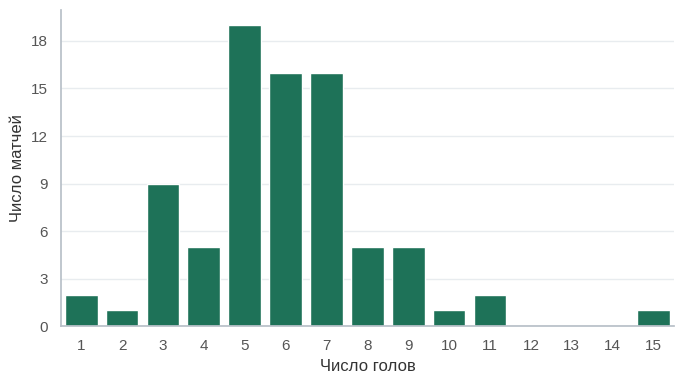

In [11]:
plt.figure(figsize=(7, 4))
all_values = list(range(games['Total Score'].min(), games['Total Score'].max() + 1))
sns.countplot(x=games['Total Score'], order=all_values, color=EMERALD)
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.yticks(range(0, 21, 3))
plt.tight_layout()
plt.savefig('figures/goals_hist.pdf')
plt.show()

In [12]:
games['Total Score'].value_counts().sort_index()

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

In [13]:
print('Доля матчей с числом голов от 4 до 7:', round(games['Total Score'].between(4, 7).mean(), 2))
print('Коэффициент асимметрии:', round(games['Total Score'].skew(), 2))

Доля матчей с числом голов от 4 до 7: 0.68
Коэффициент асимметрии: 0.78


Чаще всего в матче забивали 5 шайб (19 игр), чуть реже 6 и 7 (по 16 игр). 

Примерно две трети матчей (68%) укладываются в диапазон от 4 до 7 голов. 

Распределение несимметричное: слева оно быстро упирается в ноль, а справа у него длинный хвост из редких результативных игр на 10, 11 и 15 голов (коэффициент асимметрии 0,78). На другом краю находятся три закрытых матча с одной или двумя шайбами, два из них закончились 1:0 в овертайме.

## 6. Самые нерезультативные и самые результативные игры

Матчи отобраны сравнением с минимумом и максимумом числа голов. При таком способе в список попадают все матчи с крайним значением, если их несколько. При сортировке с выбором первой строки часть из них потерялась бы.

In [14]:
min_games = games[games['Total Score'] == games['Total Score'].min()]
min_games['Game Info'].tolist()

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [15]:
max_games = games[games['Total Score'] == games['Total Score'].max()]
max_games['Game Info'].tolist()

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Меньше всего голов (по одному) было в двух матчах, оба закончились 1:0 в овертайме. 

Больше всего голов, 15, было в матче Колорадо и Миннесоты (9:6).

## 7. Сколько игроков участвовало в каждой игре

Для каждой команды взяты 6 слотов «на льду» и столбец вратаря, всего 14 столбцов. 

Одна строка соответствует одному игроку в одном событии. Затем в каждом матче посчитано число уникальных имён. Вратарь обычно и так стоит в одном из шести слотов, но `nunique` всё равно учитывает его один раз. Пустые слоты (например, при игре в меньшинстве) удалены, тк это не игроки.

In [16]:
away_cols = ["Away Team's Player on the Ice #1", "Away Team's Player on the Ice #2",
             "Away Team's Player on the Ice #3", "Away Team's Player on the Ice #4",
             "Away Team's Player on the Ice #5", "Away Team's Player on the Ice #6",
             "Away Team's Goalie"]
home_cols = ["Home Team's Player on the Ice #1", "Home Team's Player on the Ice #2",
             "Home Team's Player on the Ice #3", "Home Team's Player on the Ice #4",
             "Home Team's Player on the Ice #5", "Home Team's Player on the Ice #6",
             "Home Team's Goalie"]

on_ice = events.melt(id_vars='Game ID', value_vars=away_cols + home_cols, value_name='Player')
on_ice = on_ice.dropna(subset=['Player'])

player_count = on_ice.groupby('Game ID')['Player'].nunique()

result = pd.DataFrame({'Game Info': games['Game Info'], 'Player Count': player_count})
result[result['Player Count'] == result['Player Count'].max()]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


In [17]:
player_count.value_counts().sort_index()

Player
38    73
39     8
40     1
Name: count, dtype: int64

Максимум получился 40, в примере задания указано 41, скорее всего, в примере пустое значение посчитано как ещё один игрок. 

Если не удалять пропуски, получается ровно 41 и тот же матч:

In [18]:
on_ice_with_nan = events.melt(id_vars='Game ID', value_vars=away_cols + home_cols, value_name='Player')
on_ice_with_nan.groupby('Game ID')['Player'].nunique(dropna=False).max()

41

По смыслу правильный ответ 40. В заявку на матч НХЛ входят 20 человек: 18 полевых и 2 вратаря. В обычном матче на лёд выходят 18 полевых и один вратарь у каждой команды, итого 38, так было в 73 играх из 82. Значение 39 означает, что одна команда меняла вратаря по ходу игры (8 матчей). В матче Монреаля с Баффало (3:8) вратарей поменяли обе команды, поэтому на лёд вышли все 40 заявленных игроков.

## 8. Расстояние от точки броска до ворот

Сначала нужно понять, в какие ворота летел бросок. Если хозяева защищают левые ворота (`left`), то сами они бросают в правые (X = 89), а гости в левые (X = -89). При значении `right` всё наоборот. Бросающая команда определена сравнением `Team Making the Play` с `Home Team`.

Расстояние посчитано по формуле из задания. Если шайба напротив створа (|y| <= 3), расстояние равно |x - X|, иначе берётся расстояние до ближайшей штанги (y = -3 или y = 3).

Поле `Home Team's Defending Side` меняется от периода к периоду, потому что команды меняются воротами. Поэтому сторона взята для каждого события отдельно, а не одна на весь матч.

In [19]:
GOAL_X = 89
POST_Y = 3

shot_types = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(shot_types)

home_shoots = events['Team Making the Play'] == events['Home Team']
home_left = events["Home Team's Defending Side"] == 'left'

goal_x = np.where(home_shoots,
                  np.where(home_left, GOAL_X, -GOAL_X),
                  np.where(home_left, -GOAL_X, GOAL_X))

x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']

dist_below = np.sqrt((x - goal_x) ** 2 + (y + POST_Y) ** 2)
dist_front = np.abs(x - goal_x)
dist_above = np.sqrt((x - goal_x) ** 2 + (y - POST_Y) ** 2)

length = np.where(y < -POST_Y, dist_below, np.where(y > POST_Y, dist_above, dist_front))
events['Shot Length'] = np.where(is_shot, length, np.nan)

events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Значения и число бросков (7266) совпадают с примером. Координаты есть у всех бросков, пропусков нет.

## 9. Длина точных и неточных бросков

Точных бросков (в створ и голов) примерно в 1,7 раза больше, чем неточных, поэтому гистограммы с количествами сравнивать неудобно (одна будет выше другой). Каждая гистограмма нормирована на свою подвыборку: в `displot` заданы `stat='density'` и `common_norm=False`, тогда площадь под каждой гистограммой равна единице.

Ширина столбца 5 футов выбрана так, чтобы при 7 тысячах бросков гистограмма не была ни слишком рваной, ни слишком сглаженной.

Shot
в створ       4623
мимо ворот    2643
Name: count, dtype: int64


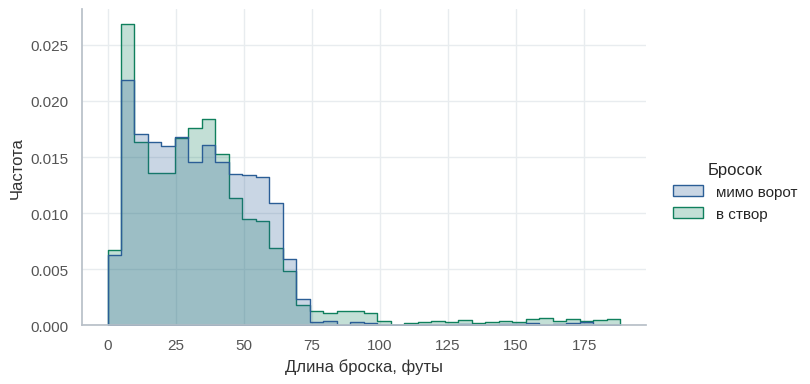

In [20]:
shots = events[is_shot].copy()
shots['Shot'] = 'в створ'
shots.loc[shots['Play Type'] == 'missed-shot', 'Shot'] = 'мимо ворот'

print(shots['Shot'].value_counts())

g = sns.displot(data=shots, x='Shot Length', hue='Shot', stat='density', common_norm=False,
                binwidth=5, height=4, aspect=1.7, element='step',
                palette={'в створ': EMERALD, 'мимо ворот': BLUE})
g.set_axis_labels('Длина броска, футы', 'Частота')
g.legend.set_title('Бросок')
plt.savefig('figures/shot_length.pdf', bbox_inches='tight')
plt.show()

In [21]:
shots.groupby('Shot')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
в створ,4623.0,36.207,29.997,0.0,15.000,31.828,47.011,188.215
мимо ворот,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068


Доли бросков каждой группы по диапазонам расстояний:

In [22]:
distance_bins = pd.cut(shots['Shot Length'], bins=[0, 10, 20, 30, 40, 50, 60, GOAL_X, 200], right=False)
pd.crosstab(distance_bins, shots['Shot'], normalize='columns')

Shot,в створ,мимо ворот
Shot Length,,
"[0, 10)",0.166,0.139
"[10, 20)",0.151,0.166
"[20, 30)",0.152,0.163
"[30, 40)",0.181,0.155
"[40, 50)",0.132,0.139
"[50, 60)",0.090,0.131
"[60, 89)",0.081,0.095
"[89, 200)",0.048,0.011


Отдельно рассмотрен хвост: броски из-за центральной красной линии, то есть дальше 89 футов от ворот, со своей половины площадки.

Граница 89 футов соответствует центральной красной линии, потому что линия ворот находится в 89 футах от центра площадки.

In [23]:
long_shots = shots[shots['Shot Length'] > GOAL_X].copy()
print('Бросков из-за красной линии:', len(long_shots))
print('Из них в створ:', round((long_shots['Shot'] == 'в створ').mean(), 3),
      ' (по всем броскам:', round((shots['Shot'] == 'в створ').mean(), 3), ')')

minutes_left = long_shots['Remaining Time'].str.split(':').str[0].astype(int)
long_shots['Last 3 min'] = (long_shots['Period'] == 3) & (minutes_left < 3)
pd.crosstab(long_shots['Play Type'], long_shots['Last 3 min'])

Бросков из-за красной линии: 251
Из них в створ: 0.88  (по всем броскам: 0.636 )


Last 3 min,False,True
Play Type,,
goal,5,14
missed-shot,12,18
shot-on-goal,193,9


In [24]:
print('Остановок из-за проброса (icing):', (events['Play Subtype'] == 'icing').sum())

Остановок из-за проброса (icing): 830


В основной части гистограммы, до синей линии соперника (около 65 футов), распределения точных и неточных бросков очень похожи. Медианы почти одинаковые (31,8 и 32,2 фута), а доли бросков в каждом диапазоне расстояний различаются не больше чем на 4 п. п. 

Точные броски немного чаще бывают с самого близкого расстояния, до 10 футов (это добивания и подставления, которые вратарь отражает в упор). 

Броски мимо немного чаще наносятся с расстояния от 50 до 60 футов. Получается, что дистанция мало влияет на то, попадёт ли бросок в створ. Попасть в рамку почти одинаково трудно и с 15, и с 45 футов, решает скорее давление защитников и качество самого броска. Заметное различие одно: длинный хвост точных бросков со своей половины поля, где неточных почти нет.

Почему в хвосте так много точных бросков:

1. Это не совсем броски. Со своей половины шайбу обычно выбрасывают из зоны, чтобы отбиться или сменить состав. Если такая шайба пересекает линию ворот мимо створа, это проброс (icing): игру останавливают, и событие записывается как `stoppage`, а не как `missed-shot` (пробросов в данных 830). Если же шайба летит в ворота и вратарь её ловит, проброса нет, и это засчитывается как бросок в створ. Поэтому из дальних бросков в данных остаются в основном точные: 88% против 64% в среднем.

2. Пустые ворота. В конце игры проигрывающая команда снимает вратаря, и тогда с любой точки можно бросать прямо в ворота. Из 19 голов из-за красной линии 14 забиты в последние три минуты третьего периода.

## 10. Доля точных бросков у каждой команды в каждой игре

Незаблокированные броски включают броски в створ, голы и броски мимо. Гол тоже считается броском в створ.

In [25]:
shots['On Goal'] = shots['Play Type'] != 'missed-shot'

numshots = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].agg(['sum', 'count'])
numshots.columns = ['Shots on Goal', 'Unblocked Shots']
numshots['Share of Shots on Goal'] = numshots['Shots on Goal'] / numshots['Unblocked Shots']

numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [26]:
numshots['Share of Shots on Goal'].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

Дальше проверено, связана ли точность с результатом: часто ли побеждает команда, у которой в этом матче доля бросков в створ выше. Для сравнения то же посчитано для простого числа бросков в створ. В каждом матче показатели победителя сравниваются с показателями проигравшего, матчи с равными значениями не учитываются.

Сравнение внутри матча удобно тем, что обе команды играют в одних условиях и друг против друга, поэтому силу соперника отдельно учитывать не нужно.

In [27]:
games['Winner'] = games['Home Team']
games.loc[games['Away Score'] > games['Home Score'], 'Winner'] = games['Away Team']

by_game = numshots.reset_index()
by_game['Winner'] = by_game['Game ID'].map(games['Winner'])
winners = by_game[by_game['Team Making the Play'] == by_game['Winner']].set_index('Game ID')
losers = by_game[by_game['Team Making the Play'] != by_game['Winner']].set_index('Game ID')

share_diff = winners['Share of Shots on Goal'] - losers['Share of Shots on Goal']
shots_diff = winners['Shots on Goal'] - losers['Shots on Goal']

print('Матчей с равной долей точных бросков:', (share_diff == 0).sum())
print('Побеждала более точная команда:', (share_diff > 0).sum(), 'из', (share_diff != 0).sum(),
      '=', round((share_diff > 0).sum() / (share_diff != 0).sum(), 3))
print('Матчей с равным числом бросков в створ:', (shots_diff == 0).sum())
print('Побеждала команда с большим числом бросков в створ:', (shots_diff > 0).sum(), 'из', (shots_diff != 0).sum(),
      '=', round((shots_diff > 0).sum() / (shots_diff != 0).sum(), 3))

Матчей с равной долей точных бросков: 0
Побеждала более точная команда: 37 из 82 = 0.451
Матчей с равным числом бросков в створ: 4
Побеждала команда с большим числом бросков в створ: 47 из 78 = 0.603


В среднем примерно 64% незаблокированных бросков команды доходят до ворот. Разброс между матчами заметный, от 35% до 86%, при этом половина значений лежит между 58% и 69%.

Сама по себе точность почти ничего не говорит о результате: команда с более высокой долей бросков в створ выиграла только 45% матчей, то есть не чаще, чем при подбрасывании монетки. Команда, которая просто чаще бросала в створ, побеждала в 60% матчей (47 из 78, ещё в 4 матчах бросков в створ было поровну). 

Скорее всего, высокая доля говорит не о силе команды, а о стиле игры. Команда, которая бросает редко и только из хороших позиций, получает высокую точность, но мало моментов. Команда, которая много давит и бросает отовсюду, часто промахивается, зато создаёт больше опасных моментов.

## 11. Самые точные и самые неточные команды

In [28]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [29]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Средняя доля здесь посчитана как среднее по матчам, как в задании, и каждый матч входит в неё с одинаковым весом. Можно посчитать иначе, сложив все броски команды за плей-офф. Тогда матчи, в которых команда бросала больше, весят сильнее. Ниже проверено, меняет ли это результат.

In [30]:
pooled = numshots.groupby('Team Making the Play')[['Shots on Goal', 'Unblocked Shots']].sum()
compare_share = pd.DataFrame({'Mean over Games': avgnumshots,
                              'All Shots': pooled['Shots on Goal'] / pooled['Unblocked Shots']})
compare_share.sort_values('Mean over Games', ascending=False)

,Mean over Games,All Shots
Team Making the Play,,
Edmonton Oilers,0.706,0.700
Philadelphia Flyers,0.684,0.681
Dallas Stars,0.670,0.669
Minnesota Wild,0.656,0.657
Colorado Avalanche,0.653,0.649
Anaheim Ducks,0.649,0.648
Montréal Canadiens,0.644,0.648
Los Angeles Kings,0.642,0.639
Boston Bruins,0.638,0.637


Ниже число сыгранных матчей и итог финала. В `Game ID` третья с конца цифра означает номер раунда, финал соответствует раунду 4.

In [31]:
games_per_team = pd.concat([games['Away Team'], games['Home Team']]).value_counts()
games_per_team

Vegas Golden Knights    22
Montréal Canadiens      19
Carolina Hurricanes     19
Buffalo Sabres          13
Colorado Avalanche      13
Anaheim Ducks           12
Minnesota Wild          11
Philadelphia Flyers     10
Tampa Bay Lightning      7
Utah Mammoth             6
Boston Bruins            6
Pittsburgh Penguins      6
Edmonton Oilers          6
Dallas Stars             6
Ottawa Senators          4
Los Angeles Kings        4
Name: count, dtype: int64

In [32]:
final = games[games.index // 100 % 10 == 4]
final['Winner'].value_counts()

Winner
Carolina Hurricanes     4
Vegas Golden Knights    2
Name: count, dtype: int64

Средняя доля точных бросков по командам меняется от 55% у Питтсбурга до 71% у Эдмонтона. Связь с успехом в турнире снова не видна. 

Эдмонтон, самая точная команда, вылетел в первом раунде (6 матчей), а Каролина с третьей с конца точностью выиграла Кубок (19 матчей). Вегас, второй финалист, тоже в нижней половине списка. Это подтверждает вывод из п. 10: точность скорее отражает манеру игры, чем силу команды.

Кроме того, у команд с короткой серией (от 4 до 6 матчей) среднее посчитано всего по нескольким играм и сильно зависит от случайности.

Если считать долю по всем броскам сразу, порядок команд меняется мало. В пятёрке самых точных остаются те же команды, в пятёрке самых неточных Оттава сменяет Баффало. Вывод от способа усреднения не зависит.

## 12. Среднее число бросков в створ и голов за игру

Броски в створ здесь включают голы. Если посчитать голы через `groupby` и взять среднее, матчи, где команда не забила ни разу, пропадут из расчёта, и среднее получится завышенным. `pd.crosstab` ставит в такие клетки ноль, поэтому использован он.

In [33]:
on_goal = shots[shots['On Goal']]
counts = pd.crosstab([on_goal['Game ID'], on_goal['Team Making the Play']], on_goal['Play Type'])
counts['Shot'] = counts['shot-on-goal'] + counts['goal']
counts['Goal'] = counts['goal']

avgshots = counts.groupby('Team Making the Play')[['Shot', 'Goal']].mean()
avgshots.columns.name = None
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


In [34]:
rows_per_team = counts.groupby('Team Making the Play').size()
print('У каждой команды строк столько же, сколько матчей:',
      (rows_per_team.sort_index() == games_per_team.sort_index()).all())

У каждой команды строк столько же, сколько матчей: True


## 13. Связь бросков в створ и голов

На графике подписаны не все 16 команд, а только выделяющиеся, иначе подписи налезают друг на друга.

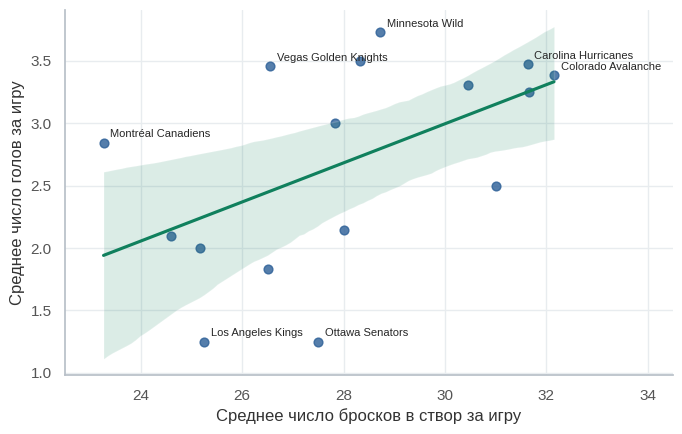

In [35]:
plt.figure(figsize=(7, 4.5))
sns.regplot(data=avgshots, x='Shot', y='Goal', color=EMERALD,
            scatter_kws={'color': BLUE, 's': 40})

labeled = ['Carolina Hurricanes', 'Vegas Golden Knights', 'Colorado Avalanche', 'Minnesota Wild',
           'Montréal Canadiens', 'Ottawa Senators', 'Los Angeles Kings']
for team in labeled:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                 textcoords='offset points', xytext=(5, 4), fontsize=8)

plt.xlim(22.5, 34.5)
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.tight_layout()
plt.savefig('figures/shots_goals.pdf')
plt.show()

In [36]:
reg = stats.linregress(avgshots['Shot'], avgshots['Goal'])
print('наклон:', round(reg.slope, 3))
print('корреляция:', round(reg.rvalue, 3), ' R^2:', round(reg.rvalue ** 2, 3))
print('p-value:', round(reg.pvalue, 3))

наклон: 0.156
корреляция: 0.521  R^2: 0.271
p-value: 0.039


In [37]:
realization = avgshots['Goal'] / avgshots['Shot']
realization.sort_values()

Team Making the Play
Ottawa Senators         0.045
Los Angeles Kings       0.050
Pittsburgh Penguins     0.069
Tampa Bay Lightning     0.077
Boston Bruins           0.079
Dallas Stars            0.081
Philadelphia Flyers     0.085
Anaheim Ducks           0.103
Colorado Avalanche      0.105
Utah Mammoth            0.108
Buffalo Sabres          0.109
Carolina Hurricanes     0.110
Montréal Canadiens      0.122
Edmonton Oilers         0.124
Minnesota Wild          0.130
Vegas Golden Knights    0.130
dtype: float64

Связь есть, но умеренная. Корреляция 0,52, бросками объясняется около 27% разброса голов между командами. 

Наклон 0,16 означает, что примерно шесть лишних бросков в створ за игру дают в среднем один лишний гол. 

При 5%-м уровне связь значима (p = 0,04), но точек всего 16, и одна или две команды заметно меняют картину, поэтому сильных выводов отсюда делать не стоит. Сильнее всего вниз от линии отклоняются Оттава и Лос-Анджелес. У них всего по 4 матча, так что их средние посчитаны по очень маленькой выборке, а в регрессии каждая команда весит одинаково.

Главное, что видно на графике, это *сильная разница в реализации*. Оттава и Лос-Анджелес бросали не меньше многих (от 25 до 28 бросков за игру), но забивали всего по 1,25 гола, то есть реализовали 4,5 и 5% бросков. У Миннесоты и Вегаса реализация 13%. Монреаль бросал меньше всех (23 броска), но за счёт реализации 12% забивал почти столько же, сколько в среднем по турниру (2,8 гола против примерно 3). То есть число бросков задаёт только примерный уровень, а дальше многое решают качество моментов, мастерство игроков и вратари соперника. 

## 14. Матч с наибольшим числом ударов

Здесь учтены все попытки: броски в створ, голы, броски мимо и заблокированные. Для заблокированных бросков `Team Making the Play` означает бросавшую команду, а блокирующий игрок записан в Player #1. Это видно по полю `Play Zone`: для заблокированных бросков почти всегда указана зона защиты, то есть зона защищающейся команды. 

In [38]:
attempt_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
attempts = events[events['Play Type'].isin(attempt_types)].copy()

attempts_per_game = attempts.groupby('Game ID').size()
idxmax = attempts_per_game.idxmax()

print(gameInfo(idxmax))
print('Ударов в матче:', attempts_per_game.max())
attempts_per_game.describe()

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Ударов в матче: 208


count     82.000
mean     122.732
std       19.568
min       93.000
25%      111.500
50%      120.000
75%      134.750
max      208.000
dtype: float64

Это матч Каролины и Оттавы с двумя овертаймами: 208 ударов при медиане по турниру 120. Ниже проверено, не объясняется ли это просто длительностью матча. Длительность посчитана как полные периоды по 20 минут плюс время финальной сирены в последнем периоде.

In [39]:
PERIOD_MIN = 20

ends = events[events['Play Type'] == 'game-end'].set_index('Game ID')
end_min = ends['Elapsed Time'].str.split(':').str[0].astype(int)
end_sec = ends['Elapsed Time'].str.split(':').str[1].astype(int)
games['Minutes'] = (ends['Period'] - 1) * PERIOD_MIN + end_min + end_sec / 60

games['Attempts'] = attempts_per_game
games['Attempts per 60'] = games['Attempts'] / games['Minutes'] * 60

print('Длительность матча, мин:', round(games.loc[idxmax, 'Minutes'], 1))
print('Ударов за 60 минут:', round(games.loc[idxmax, 'Attempts per 60'], 1))
print('Место по ударам за 60 минут:', int(games['Attempts per 60'].rank(ascending=False)[idxmax]), 'из', len(games))
games['Attempts per 60'].describe()

Длительность матча, мин: 93.9
Ударов за 60 минут: 132.9
Место по ударам за 60 минут: 9 из 82


count     82.000
mean     116.074
std       12.466
min       93.000
25%      108.169
50%      116.000
75%      125.247
max      141.000
Name: Attempts per 60, dtype: float64

Матч шёл почти 94 минуты, и в пересчёте на 60 минут в нём было около 133 ударов. Это 9 место из 82 (максимум 141), так что игра действительно была атакующей. Но первое место по общему числу ударов она получила в основном за счёт двух овертаймов.

## 15. Карта ударов этого матча

По заданию удары гостей нарисованы так, будто они бьют в левые ворота, а удары хозяев так, будто в правые. Для этого координаты в нечётных периодах отражены: (x, y) -> (-x, -y). Сначала проверено, что это правило подходит для этого матча, то есть что хозяева в нечётных периодах защищают правые ворота.

In [40]:
game_shots = attempts[attempts['Game ID'] == idxmax].copy()
pd.crosstab(game_shots['Period'], game_shots["Home Team's Defending Side"])

Home Team's Defending Side,left,right
Period,,
1,0,46
2,45,0
3,0,40
4,42,0
5,0,35


Верно: в 1, 3 и 5 периодах ворота хозяев справа, значит, бьют они в левые, и эти периоды нужно отразить. После отражения медиана x у хозяев должна быть положительной, у гостей отрицательной.

In [41]:
game_shots['x'] = game_shots['X Coordinate on the Ice Rink']
game_shots['y'] = game_shots['Y Coordinate on the Ice Rink']

odd = game_shots['Period'] % 2 == 1
game_shots.loc[odd, 'x'] = -game_shots.loc[odd, 'x']
game_shots.loc[odd, 'y'] = -game_shots.loc[odd, 'y']

game_shots.groupby('Team Making the Play')['x'].median()

Team Making the Play
Carolina Hurricanes    65.0
Ottawa Senators       -70.0
Name: x, dtype: float64

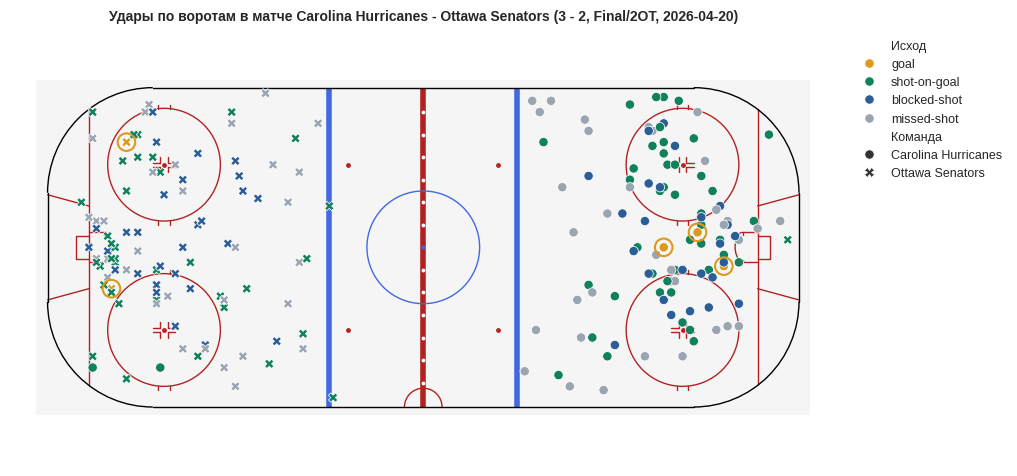

In [42]:
game_shots['Исход'] = game_shots['Play Type']
game_shots['Команда'] = game_shots['Team Making the Play']

plt.figure(figsize=(10, 4.6))
plot_rink()
ax = sns.scatterplot(data=game_shots, x='x', y='y', hue='Исход', style='Команда',
                     hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                     palette=[AMBER, EMERALD, BLUE, SILVER], s=45)

goals_only = game_shots[game_shots['Исход'] == 'goal']
plt.scatter(goals_only['x'], goals_only['y'], s=160, facecolors='none', edgecolors=AMBER, linewidths=1.5)

plt.axis('equal')
plt.axis('off')
plt.title('Удары по воротам в матче ' + gameInfo(idxmax), fontsize=10)
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
plt.tight_layout(pad=0.1)
plt.savefig('figures/rink_game.pdf', bbox_inches='tight')
plt.show()

In [43]:
pd.crosstab(game_shots['Team Making the Play'], game_shots['Play Type'], margins=True)

Play Type,blocked-shot,goal,missed-shot,shot-on-goal,All
Team Making the Play,,,,,
Carolina Hurricanes,26,3,34,46,109
Ottawa Senators,28,2,32,37,99
All,54,5,66,83,208


In [44]:
unblocked = game_shots[game_shots['Play Type'] != 'blocked-shot']
print('Дистанция незаблокированных бросков, футы:')
print(unblocked.groupby('Team Making the Play')['Shot Length'].describe())
print()
print(game_shots[game_shots['Play Type'] == 'goal'][['Period', 'Team Making the Play', 'Shot Length']])

Дистанция незаблокированных бросков, футы:
                      count    mean     std  min     25%     50%     75%     max
Team Making the Play                                                            
Carolina Hurricanes    83.0  35.702  27.355  2.0  20.815  30.610  45.673  179.36
Ottawa Senators        71.0  32.594  27.111  2.0  10.628  27.731  48.482  186.00

      Period Team Making the Play  Shot Length
5097       1  Carolina Hurricanes        9.220
5219       2  Carolina Hurricanes       16.031
5237       2      Ottawa Senators       10.000
5270       2      Ottawa Senators       26.926
5602       5  Carolina Hurricanes       25.000


In [45]:
blocked = game_shots[game_shots['Play Type'] == 'blocked-shot']
print('Расстояние от точки блока до линии ворот, футы:')
(GOAL_X - blocked['x'].abs()).describe()

Расстояние от точки блока до линии ворот, футы:


count    54.000
mean     22.370
std      11.839
min       0.000
25%      13.000
50%      23.000
75%      29.000
max      50.000
Name: x, dtype: float64

По числу ударов команды почти равны (109 у Каролины и 99 у Оттавы), но в створ Каролина попадала чаще: 49 бросков в створ вместе с голами против 39 у Оттавы. Все пять голов (жёлтые точки в кольцах) забиты с близкого расстояния, от 9 до 27 футов, то есть из слота и с пятачка. Заблокированные удары (синие) сосредоточены не у синей линии, а внутри зоны, в районе кругов вбрасывания (медиана около 23 футов от линии ворот). Защитники встают на пути броска, когда соперник уже вошёл в зону. Броски мимо (серые) разбросаны сильнее всего, многие нанесены от синей линии и из-под острых углов. Интересно, что Оттава чаще бросала совсем близко к воротам: четверть её незаблокированных бросков нанесена ближе 11 футов, у Каролины ближе 21 фута. Но реализовала эти моменты Оттава хуже, и матч выиграла Каролина.

## 16. Лучшие бомбардиры

Если на границе десятки несколько игроков набрали одинаково, показаны все.

In [46]:
goal_events = events[events['Play Type'] == 'goal'].copy()

goals_by_player = goal_events['Player in the Event #1'].value_counts()
top_scorers = goals_by_player.nlargest(10, keep='all')

scorer_team = goal_events.groupby('Player in the Event #1')['Team Making the Play'].first()
pd.DataFrame({'Goals': top_scorers, 'Team': scorer_team[top_scorers.index]})

,Goals,Team
Player in the Event #1,,
Brett Howden,14,Vegas Golden Knights
Pavel Dorofeyev,12,Vegas Golden Knights
Logan Stankoven,11,Carolina Hurricanes
Mitch Marner,10,Vegas Golden Knights
Nikolaj Ehlers,8,Carolina Hurricanes
Jordan Staal,8,Carolina Hurricanes
Matt Boldy,7,Minnesota Wild
Nathan MacKinnon,7,Colorado Avalanche
Alex Newhook,7,Montréal Canadiens


Больше всех забил Бретт Хауден (14 голов), за ним Павел Дорофеев (12) и Логан Станковен (11). Десятое место делят шесть игроков с 7 голами, поэтому в списке 12 фамилий. Первые шесть мест и 9 позиций из 12 занимают игроки финалистов, Вегаса и Каролины. Это неудивительно: они провели больше всего матчей (22 и 19), а абсолютное число голов растёт с числом игр.

## 17. Лучшие ассистенты

Первая и вторая передачи считаются одинаково.

In [47]:
assists = pd.concat([goal_events['Player in the Event #2'], goal_events['Player in the Event #3']])
assists_by_player = assists.value_counts()
assists_by_player.nlargest(10, keep='all')

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Shea Theodore      12
Martin Necas       12
Taylor Hall        12
Nick Suzuki        12
Quinn Hughes       11
Kirill Kaprizov    11
Name: count, dtype: int64

Лидер по передачам Джек Айкел (20), за ним Митч Марнер (19). Здесь на границе десятки ничьей нет, в списке ровно 10 игроков.

## 18. Лучшие по системе *гол + пас*

У некоторых игроков есть голы, но нет передач, или наоборот, поэтому пропуски заменены нулями.

In [48]:
points = goals_by_player.add(assists_by_player, fill_value=0).astype(int)

top_points = pd.DataFrame({'Goals': goals_by_player, 'Assists': assists_by_player, 'Points': points})
top_points = top_points.fillna(0).astype(int)
top_points.nlargest(10, 'Points', keep='all')

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Lane Hutson,3,13,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


С большим отрывом лидирует Митч Марнер: 29 очков (10 голов и 19 передач). Дальше идут Айкел (22) и Джексон Блейк (20). Десятое место делят четыре игрока с 16 очками, поэтому в списке 11 человек.

## 19. Больше всего бросков в створ за игру

Для среднего за игру нужно знать, сколько матчей сыграл каждый игрок. Матч засчитан игроку, если он хотя бы раз был на льду (таблица `on_ice` из п. 7). Автор броска записан в Player #1, у голов там автор гола, так что голы тоже учтены как броски в створ.

Если считать матчи только по событиям, где игрок что-то сделал, у тех, кто выходил на лёд, но не бросал, число матчей было бы занижено, а среднее завышено.

In [49]:
games_played = on_ice[['Game ID', 'Player']].drop_duplicates()['Player'].value_counts()

shooters = shots[shots['On Goal']]['Player in the Event #1'].value_counts()

players = pd.DataFrame({'Games': games_played})
players['Shots on Goal'] = shooters
players['Shots on Goal'] = players['Shots on Goal'].fillna(0)
players['Shots per Game'] = players['Shots on Goal'] / players['Games']

players.nlargest(10, 'Shots per Game', keep='all')

,Games,Shots on Goal,Shots per Game
Player,,,
Jason Robertson,6,30.0,5.000
Dylan Guenther,6,27.0,4.500
Nikita Kucherov,7,31.0,4.429
Matt Boldy,11,48.0,4.364
Quinton Byfield,4,17.0,4.250
Darren Raddysh,7,28.0,4.000
Joel Eriksson Ek,6,24.0,4.000
Alex Laferriere,4,15.0,3.750
David Pastrnak,6,22.0,3.667


Первое место у Джейсона Робертсона (5 бросков за игру), второе у Дилана Гюнтера (4,5), третье у Никиты Кучерова (4,4). Все трое играли за команды, которые вылетели в первом раунде, поэтому их среднее посчитано по 6 или 7 матчам. Среди сыгравших больше 10 матчей выше всех Мэтт Болди (4,4 за 11 игр) и Натан Маккиннон (3,6 за 13 игр).

## 20. Больше всего силовых приёмов за игру

In [50]:
hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()

players['Hits'] = hits
players['Hits'] = players['Hits'].fillna(0)
players['Hits per Game'] = players['Hits'] / players['Games']

players.nlargest(10, 'Hits per Game', keep='all')[['Games', 'Hits', 'Hits per Game']]

,Games,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38.0,6.333
Alexander Petrovic,1,6.0,6.000
Alex Turcotte,1,6.0,6.000
Yakov Trenin,9,51.0,5.667
Dylan Cozens,4,22.0,5.500
Vasily Podkolzin,6,32.0,5.333
Ivan Barbashev,22,110.0,5.000
Marcus Foligno,11,55.0,5.000
Carl Grundstrom,3,15.0,5.000


Здесь в десятку попадают двое, сыгравших всего один матч (Петрович и Туркотт, по 6 силовых в этой игре). Формально ответ правильный, но одной игры слишком мало. Поэтому дополнительно приведён тот же список только для игроков, сыгравших хотя бы 4 матча (минимальная длина серии):

In [51]:
regular = players[players['Games'] >= 4]
regular.nlargest(10, 'Hits per Game', keep='all')[['Games', 'Hits', 'Hits per Game']]

,Games,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38.0,6.333
Yakov Trenin,9,51.0,5.667
Dylan Cozens,4,22.0,5.500
Vasily Podkolzin,6,32.0,5.333
Ivan Barbashev,22,110.0,5.000
Marcus Foligno,11,55.0,5.000
Owen Tippett,6,29.0,4.833
William Carrier,19,91.0,4.789
Colton Dach,5,23.0,4.600


Самый «силовой» игрок турнира Лоусон Круз (6,3 силовых за игру). По общему числу выделяется Иван Барбашёв: 110 силовых за 22 матча, по 5 за игру на протяжении всего плей-офф.

## 21. Вратари, которые хотя бы в одном матче не пропустили ни одного гола

Для каждого гола определён вратарь, который его пропустил (если забили хозяева, то вратарь гостей, и наоборот). 

Затем посчитаны пропущенные голы каждого вратаря в каждом матче и найдены пары «вратарь, матч» с нулём пропущенных.

У голов, которые завершили матч в овертайме, не заполнены составы на льду: 0 игроков, вратари NaN.

In [52]:
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]

no_lineup = goal_events["# of Away Team's Players on the Ice"] == 0
print('Голов без составов на льду:', no_lineup.sum())
goal_events[no_lineup][['Game ID', 'Period', 'Team Making the Play'] + goalie_cols].head()

Голов без составов на льду: 22


,Game ID,Period,Team Making the Play,Away Team's Goalie,Home Team's Goalie
1853,2025030115,4,Boston Bruins,NaN,NaN
2548,2025030121,4,Montréal Canadiens,NaN,NaN
2977,2025030122,4,Tampa Bay Lightning,NaN,NaN
3296,2025030123,4,Montréal Canadiens,NaN,NaN
4351,2025030126,4,Tampa Bay Lightning,NaN,NaN


Это ровно 22 гола, по числу матчей с овертаймом. Без исправления получится, что эти голы никто не пропускал. Тогда, например, вратари Монреаля и Питтсбурга, проигравшие 0:1 в овертайме, попадут в список как не пропустившие ни одного гола, хотя на самом деле пропустили. Поэтому для таких голов вратари взяты из предыдущего события того же матча (секундой раньше на льду те же вратари). Голы, у которых вратарь остаётся пустым и после этого, забиты в пустые ворота, их не пропускал никто.

In [53]:
prev_goalies = events.groupby('Game ID')[goalie_cols].shift(1)
fix_index = goal_events.index[no_lineup]
goal_events.loc[fix_index, goalie_cols] = prev_goalies.loc[fix_index, goalie_cols]
print('Пустых вратарей у исправленных голов:', goal_events.loc[fix_index, goalie_cols].isna().sum().sum())

goal_events['Conceded By'] = np.where(goal_events['Team Making the Play'] == goal_events['Home Team'],
                                      goal_events["Away Team's Goalie"], goal_events["Home Team's Goalie"])

print('Голов в пустые ворота:', goal_events['Conceded By'].isna().sum())

Пустых вратарей у исправленных голов: 0
Голов в пустые ворота: 3


Для каждого вратаря посчитано число пропущенных голов в каждом матче. Доля событий матча, в которых вратарь был на льду, показывает, играл ли он весь матч или вышел на замену.

In [54]:
goalies = events.melt(id_vars='Game ID', value_vars=goalie_cols, value_name='Goalie')
goalies = goalies.dropna(subset=['Goalie'])
goalie_games = goalies.groupby(['Game ID', 'Goalie']).size().reset_index(name='Events')

conceded = goal_events.groupby(['Game ID', 'Conceded By']).size().reset_index(name='Goals Against')
conceded = conceded.rename(columns={'Conceded By': 'Goalie'})

goalie_games = goalie_games.merge(conceded, on=['Game ID', 'Goalie'], how='left')
goalie_games['Goals Against'] = goalie_games['Goals Against'].fillna(0).astype(int)

events_per_game = events.groupby('Game ID').size()
goalie_games['Share of Game'] = goalie_games['Events'] / goalie_games['Game ID'].map(events_per_game)

clean = goalie_games[goalie_games['Goals Against'] == 0].copy()
clean['Game Info'] = clean['Game ID'].map(games['Game Info'])
clean[['Goalie', 'Game Info', 'Share of Game']].sort_values('Goalie')

,Goalie,Game Info,Share of Game
24,Andrei Vasilevskiy,Montréal Canadiens - Tampa Bay Lightning (0 - ...,0.992
172,Brandon Bussi,Vegas Golden Knights - Carolina Hurricanes (0 ...,1.000
38,Dan Vladar,Pittsburgh Penguins - Philadelphia Flyers (0 -...,1.000
47,Dan Vladar,Philadelphia Flyers - Pittsburgh Penguins (1 -...,0.987
28,Frederik Andersen,"Carolina Hurricanes - Ottawa Senators (2 - 0, ...",0.989
111,Frederik Andersen,Carolina Hurricanes - Philadelphia Flyers (3 -...,1.000
149,Frederik Andersen,Montréal Canadiens - Carolina Hurricanes (0 - ...,1.000
9,Joonas Korpisalo,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",0.237
129,Scott Wedgewood,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...",0.637


In [55]:
sorted(clean['Goalie'].unique())

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Таких вратарей шесть. Фредерик Андерсен (Каролина) сыграл на ноль три матча, Дан Владарж (Филадельфия) два, Брэндон Бусси, Андрей Василевский, Йоонас Корписало и Скотт Веджвуд по одному. Корписало и Веджвуд выходили на замену и провели на льду примерно четверть и две трети матча соответственно. Для них условие «не пропустил ни одного гола» тоже выполнено.

В конце матчей бывают голы в пустые ворота, когда вратарь уже снят, а в данных он иногда всё ещё числится на льду (те самые голы из-за красной линии из п. 9). Если бы у какого-то вратаря все пропущенные в матче голы были такими, его тоже следовало бы добавить в список. Проверка:

In [56]:
goal_events['Long Goal'] = goal_events['Shot Length'] > GOAL_X
check = goal_events.groupby(['Game ID', 'Conceded By'])['Long Goal'].agg(['sum', 'count'])
check[check['sum'] == check['count']]

,,sum,count
Game ID,Conceded By,,


Таких случаев нет.

## 22. Свой вопрос: насколько шанс забить зависит от дистанции и кто реализовывал моменты лучше ожидаемого?

В п. 13 было видно, что при похожем числе бросков команды забивают очень по-разному. Цель этого пункта понять, в чём дело: в том, откуда команды бросают, или в том, как они реализуют свои моменты. 

Для этого построена простая модель ожидаемых голов: для каждого незаблокированного броска вероятность гола оценена по тому, с какого расстояния он нанесён. Затем для каждой команды реальные голы сравниваются с ожидаемыми.

Броски из-за красной линии (дальше 89 футов) исключены. Как выяснилось в п. 9, это в основном выбросы шайбы и броски в пустые ворота, они бы исказили оценку.

In [57]:
xg_shots = shots[shots['Shot Length'] <= GOAL_X].copy()
xg_shots['Goal'] = xg_shots['Play Type'] == 'goal'
xg_shots['Distance'] = pd.cut(xg_shots['Shot Length'], bins=[0, 10, 20, 30, 40, 50, 60, GOAL_X + 1], right=False,
                              labels=['0-10', '10-20', '20-30', '30-40', '40-50', '50-60', '60-89'])

conversion = xg_shots.groupby('Distance', observed=True)['Goal'].agg(['mean', 'sum', 'count'])
conversion.columns = ['Goal Rate', 'Goals', 'Shots']
conversion

,Goal Rate,Goals,Shots
Distance,,,
0-10,0.118,134,1137
10-20,0.099,113,1136
20-30,0.085,96,1132
30-40,0.055,69,1244
40-50,0.027,26,976
50-60,0.025,19,764
60-89,0.016,10,626


Шаг 10 футов выбран так, чтобы в каждой группе было не меньше 600 бросков и доля голов оценивалась устойчиво. Последняя группа шире, от 60 до 89 футов, потому что дальних бросков меньше.

Ожидаемые голы броска равны доле голов среди бросков с той же дистанции. Сумма по броскам команды даёт её ожидаемое число голов.

In [58]:
xg_shots['xG'] = xg_shots.groupby('Distance', observed=True)['Goal'].transform('mean')

team_xg = xg_shots.groupby('Team Making the Play')[['Goal', 'xG']].sum()
team_xg.columns = ['Goals', 'xG']
team_xg['Games'] = games_per_team
team_xg['Goals - xG'] = team_xg['Goals'] - team_xg['xG']
team_xg['Goals - xG per Game'] = team_xg['Goals - xG'] / team_xg['Games']
team_xg['Goals / xG'] = team_xg['Goals'] / team_xg['xG']
team_xg.sort_values('Goals - xG', ascending=False)

,Goals,xG,Games,Goals - xG,Goals - xG per Game,Goals / xG
Team Making the Play,,,,,,
Minnesota Wild,38,29.959,11,8.041,0.731,1.268
Vegas Golden Knights,70,62.460,22,7.540,0.343,1.121
Montréal Canadiens,54,46.705,19,7.295,0.384,1.156
Edmonton Oilers,21,15.315,6,5.685,0.948,1.371
Carolina Hurricanes,65,62.056,19,2.944,0.155,1.047
Colorado Avalanche,41,39.867,13,1.133,0.087,1.028
Utah Mammoth,18,17.087,6,0.913,0.152,1.053
Anaheim Ducks,37,36.277,12,0.723,0.060,1.020
Philadelphia Flyers,21,21.829,10,-0.829,-0.083,0.962


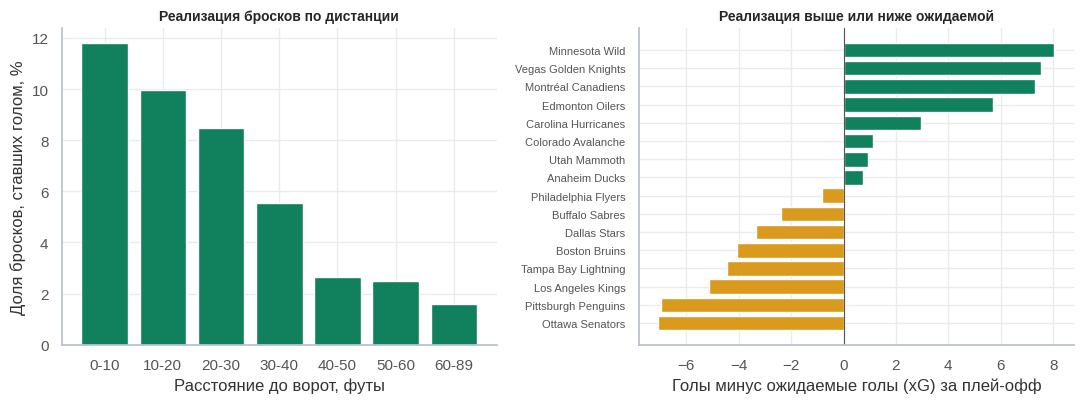

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].bar(conversion.index.astype(str), conversion['Goal Rate'] * 100, color=EMERALD)
axes[0].set_xlabel('Расстояние до ворот, футы')
axes[0].set_ylabel('Доля бросков, ставших голом, %')
axes[0].set_title('Реализация бросков по дистанции', fontsize=10)

ordered = team_xg.sort_values('Goals - xG')
colors = np.where(ordered['Goals - xG'] > 0, EMERALD, AMBER)
axes[1].barh(ordered.index, ordered['Goals - xG'], color=colors)
axes[1].axvline(0, color='#555555', linewidth=0.8)
axes[1].set_xlabel('Голы минус ожидаемые голы (xG) за плей-офф')
axes[1].set_title('Реализация выше или ниже ожидаемой', fontsize=10)
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.savefig('figures/xg.pdf', bbox_inches='tight')
plt.show()

Проверка: правда ли, что команды, забившие больше ожидаемого, бросают с более близкого расстояния?

In [60]:
team_xg['Mean Distance'] = xg_shots.groupby('Team Making the Play')['Shot Length'].mean()
print('Корреляция средней дистанции и Goals/xG:',
      round(team_xg['Mean Distance'].corr(team_xg['Goals / xG']), 2))
team_xg['Mean Distance'].describe()

Корреляция средней дистанции и Goals/xG: 0.1


count    16.000
mean     32.023
std       1.304
min      29.359
25%      31.212
50%      32.508
75%      32.826
max      33.605
Name: Mean Distance, dtype: float64

Чем ближе к воротам, тем выше шанс забить. 

С расстояния до 10 футов голом становится почти 12% бросков, с 30 до 40 футов 5,5%, а дальше 40 футов всего от 1,5 до 3%. Получается, что бросок с пятачка примерно в 7 раз опаснее броска с синей линии.

По сумме ожидаемых голов модель хорошо повторяет реальные голы, но у отдельных команд расхождения большие. Миннесота забила на 8 голов больше, чем положено по её броскам (38 против 30), Вегас и Монреаль примерно на 7,5. Эдмонтон за 6 матчей забил на 5,7 гола больше ожидаемого, почти по голу за игру. На другом краю Оттава (5 голов при 12 ожидаемых), Питтсбург (11 при 18) и Лос-Анджелес (5 при 10). Именно эти команды выделялись в п. 13.

При этом средняя дистанция бросков у команд почти одинаковая (от 29 до 34 футов) и почти не связана с тем, насколько команда превосходит ожидания (корреляция 0,1). Значит, разницу между командами создаёт не расстояние, а то, чего модель не видит: угол броска, добивания, броски в большинстве, мастерство бросающих и игра вратарей соперника. И, конечно, случайность: в серии из 4, 5 или 6 матчей разница в 5 голов может быть просто везением. Например, Оттава все 4 матча играла против Каролины, и в одном из них Андерсен не пропустил ни одного гола.

 Модель учитывает только расстояние и оценена на тех же данных, к которым применяется, поэтому её стоит воспринимать лишь как грубую оценку.

## Итог

- В среднем за матч забивали 5,9 шайбы, 22 игры из 82 дошли до овертайма.
- Точность бросков с результатом связана слабо. Более точная команда выигрывала только 45% матчей, а команда, которая чаще бросала в створ, 60%. Чемпион Каролина по точности третья с конца.
- Голы растут вместе с бросками в створ, но связь умеренная (корреляция 0,52).
- Сильнее всего на шанс забить влияет дистанция. С расстояния до 10 футов голом становится 11,8% бросков, с 60 футов и дальше только 1,6%.
- По модели ожидаемых голов Миннесота забила на 8 голов больше, чем можно было ждать по её броскам, а Оттава на 7 меньше.
- В данных нашлись две ловушки. У победных голов в овертайме пустые составы на льду (п. 21), а пустые слоты в составах легко посчитать за игроков (п. 7).